Classification -> o/p -> Categories.

If 2 Categories -> Binary Classification.

Suppose 1000 DataPoints -> 900 yes and 100 No, Ratio is 9:1  Such situation is imbalanced dataset.

What happens in ML model creating, when you train, which will be responsible in predicting, it get baised towards the max no. of data points because of imbalanced data points. 

So its necessary to fix this imbalanced dataset, and we will try to make this both the data points equal. We can do this by using Two Techniques: 1. UpSampling 2. DownSampling.

In Upsampling we can increase the data points from 100 which in minority,
In Downsampling Try to reduce the data points from 900 which in majority.




In [64]:
!pip install scikit-learn

In [65]:
import numpy as np
import pandas as pd

# Set the random seed for reproducibility
np.random.seed(123)

# Create a dataframe with two classes
n_samples = 1000
class_0_ratio = 0.9
n_class_0 = int(n_samples * class_0_ratio)
n_class_1 = n_samples - n_class_0

In [66]:
n_class_0,n_class_1

(900, 100)

In [67]:
# The seed makes the random results reproducible.

loc   → where the distribution is centered

scale → how spread out the values are

size  → how many values to generate

In [68]:
## Create my DataFrame with Imbalanced Dataset.
class_0 = pd.DataFrame({
    'feature_1' : np.random.normal(loc=0, scale=1, size=n_class_0),
    'feature_2' : np.random.normal(loc=0, scale=1, size=n_class_0),
    'target': [0] * n_class_0
})

class_1 = pd.DataFrame({
    'feature_1' : np.random.normal(loc=2, scale=1, size=n_class_1),
    'feature_2' : np.random.normal(loc=2, scale=1, size=n_class_1),
    'target': [1] * n_class_1
})

In [69]:
class_0.head()

,feature_1,feature_2,target
0,-1.085631,0.551302,0
1,0.997345,0.419589,0
2,0.282978,1.815652,0
3,-1.506295,-0.252750,0
4,-0.578600,-0.292004,0


In [70]:
class_1.head()

,feature_1,feature_2,target
0,1.699768,2.139033,1
1,1.367739,2.025577,1
2,1.795683,1.803557,1
3,2.213696,3.312255,1
4,3.033878,3.187417,1


In [71]:
df=pd.concat([class_0, class_1]).reset_index(drop=True)

In [72]:
df.head()

,feature_1,feature_2,target
0,-1.085631,0.551302,0
1,0.997345,0.419589,0
2,0.282978,1.815652,0
3,-1.506295,-0.252750,0
4,-0.578600,-0.292004,0


In [73]:
df['target'].value_counts()

target
0    900
1    100
Name: count, dtype: int64

In [74]:
## upsampling
df_minority=df[df['target']==1]
df_majority=df[df['target']==0]

In [75]:
from sklearn.utils import resample
df_minority_upsampled = resample(df_minority, replace=True, #Sample with replacement (means: A row that has already been selected can be selected again.)
         n_samples=len(df_majority), 
         random_state=42
         )

In [76]:
df_minority_upsampled.shape

(900, 3)

In [77]:
df_minority_upsampled.head()

,feature_1,feature_2,target
951,1.125854,1.843917,1
992,2.196570,1.397425,1
914,1.932170,2.998053,1
971,2.272825,3.034197,1
960,2.870056,1.550485,1


In [78]:
df_upsampled = pd.concat([df_majority,df_minority_upsampled])

In [79]:
df_upsampled['target'].value_counts()

target
0    900
1    900
Name: count, dtype: int64

Down Sampling


In [80]:
## Create my DataFrame with Imbalanced Dataset.
class_0 = pd.DataFrame({
    'feature_1' : np.random.normal(loc=0, scale=1, size=n_class_0),
    'feature_2' : np.random.normal(loc=0, scale=1, size=n_class_0),
    'target': [0] * n_class_0
})

class_1 = pd.DataFrame({
    'feature_1' : np.random.normal(loc=2, scale=1, size=n_class_1),
    'feature_2' : np.random.normal(loc=2, scale=1, size=n_class_1),
    'target': [1] * n_class_1
})

df = pd.concat([class_0, class_1]).reset_index(drop=True)

# Check the class distribution
print(df['target'].value_counts())

target
0    900
1    100
Name: count, dtype: int64


In [81]:
## downsampling
df_minority=df[df['target']==1]
df_majority=df[df['target']==0]

In [82]:
df_majority_downsampled = resample(df_majority, replace=False, #Sample with replacement
         n_samples=len(df_minority), 
         random_state=42
         )

In [83]:
df_majority_downsampled.shape

(100, 3)

In [84]:
df_downsampled = pd.concat([df_minority, df_majority_downsampled])

In [85]:
df_downsampled.target.value_counts()

target
1    100
0    100
Name: count, dtype: int64

In [86]:
from sklearn.datasets import make_classification

In [87]:
X,y = make_classification(n_samples=1000,n_redundant=0,n_features=2,n_clusters_per_class=1,weights=[0.90],random_state=12)

In [88]:
X,y

(array([[-0.76289759, -0.70680807],
        [-1.07543571, -1.0511621 ],
        [-0.61011459, -0.90980157],
        ...,
        [-1.32643852, -1.815178  ],
        [-0.83348573, -0.5146474 ],
        [-0.30287558, -0.57597532]], shape=(1000, 2)),
 array([0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0,
        0, 0

In [89]:
import pandas as pd
df1 = pd.DataFrame(X,columns=['f1','f2'])
df2 = pd.DataFrame(y,columns=['Target'])
final_df = pd.concat([df1,df2],axis=1)
final_df.head()

,f1,f2,Target
0,-0.762898,-0.706808,0
1,-1.075436,-1.051162,0
2,-0.610115,-0.909802,0
3,-2.023284,-0.428945,1
4,-0.812921,-1.316206,0


In [90]:
final_df['Target'].value_counts()

Target
0    900
1    100
Name: count, dtype: int64

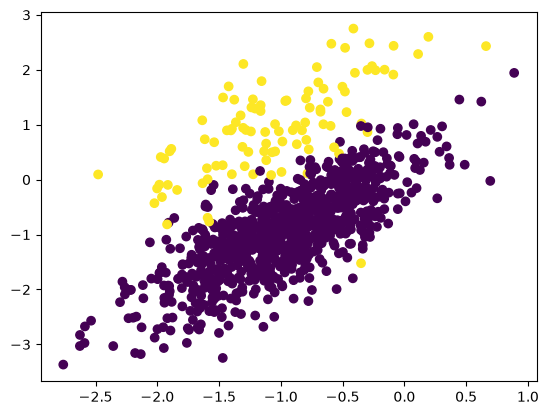

In [91]:
import matplotlib.pyplot as plt
plt.scatter(final_df['f1'], final_df['f2'], c=final_df['Target'])

In [92]:
!pip install imblearn

In [93]:
from imblearn.over_sampling import SMOTE

In [94]:
#transform the dataset
oversample=SMOTE()
X,y=oversample.fit_resample(final_df[['f1','f2']],final_df['Target'])

In [95]:
len(y[y==0])

900

In [96]:
len(y[y==1])

900

In [97]:
df1=pd.DataFrame(X,columns=['f1','f2'])
df2=pd.DataFrame(y,columns=['Target'])
oversampled_df = pd.concat([df1,df2],axis=1)

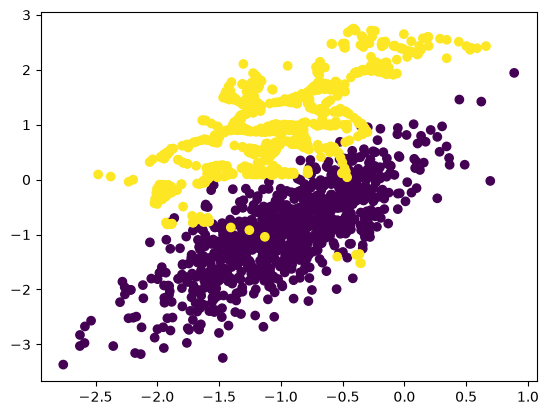

In [98]:
plt.scatter(oversampled_df['f1'], oversampled_df['f2'], c=oversampled_df['Target'])

In [9]:
import numpy as np

In [10]:
lst_marks=[45,32,56,72,89,54,32,89,90,87,67,54,45,98,99,67,74]
minimum,Q1,median,Q3,maximum=np.quantile(lst_marks,[0,0.25,0.50,0.75,1.0])

In [11]:
print(minimum,Q1,median,Q3,maximum)

32.0 54.0 67.0 89.0 99.0


In [12]:
IQR=Q3-Q1
print(IQR)

35.0


In [13]:
lower_fence=Q1-1.5*(IQR)
higher_fence=Q3+1.5*(IQR)

In [5]:
import seaborn as sns

<Axes: >

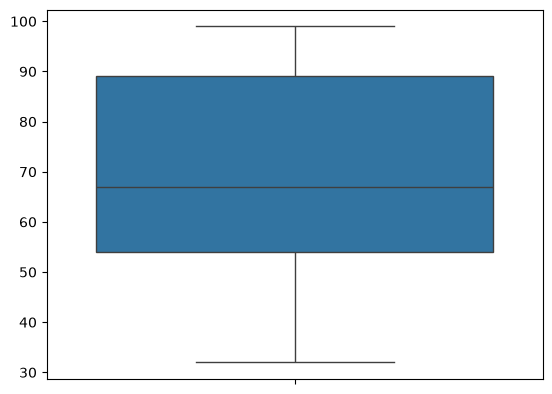

In [6]:
sns.boxplot(lst_marks)

In [7]:
lst_marks=[-100,-200,45,32,56,72,89,54,32,89,90,87,67,54,45,98,99,67,74]

<Axes: >

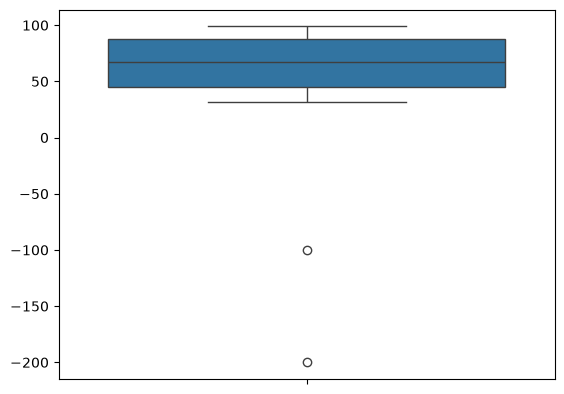

In [8]:
sns.boxplot(lst_marks)

DATA ENCODING 
NOMINAL/OHE ENCODING 
2.LABEL AND ORDINAL ENCODING

OneHotEncoder

is a class provided by scikit-learn         

creates an instance of that class

encoder is the variable that refers to the created object

think of it as a tool that knows how to convert categorical values into binary columns containing 0s and 1s

In [15]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

In [16]:
df=pd.DataFrame({
    'Color':['Red','Blue','Green','Red','Blue']
})

In [17]:
df.head()

,Color
0,Red
1,Blue
2,Green
3,Red
4,Blue


In [19]:
#create an instance of OneHotEncoder
encoder=OneHotEncoder()

In [20]:
encoded=encoder.fit_transform(df[['Color']]).toarray()
encoded

array([[0., 0., 1.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.]])

get_feature_names_out() retrives the feature names generated by the fitted encoder

In [22]:
encoder_df=pd.DataFrame(encoded,columns=encoder.get_feature_names_out())
encoder_df

,Color_Blue,Color_Green,Color_Red
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,1.0,0.0
3,0.0,0.0,1.0
4,1.0,0.0,0.0


In [23]:
pd.concat([df,encoder_df],axis=1)

,Color,Color_Blue,Color_Green,Color_Red
0,Red,0.0,0.0,1.0
1,Blue,1.0,0.0,0.0
2,Green,0.0,1.0,0.0
3,Red,0.0,0.0,1.0
4,Blue,1.0,0.0,0.0


In [24]:
#for new data
encoder.transform([['Red']]).toarray()

c:\Users\Manvitha Acharya\anaconda3\envs\myenv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but OneHotEncoder was fitted with feature names
  warnings.warn(


array([[0., 0., 1.]])

In [ ]:
encoder.transform([['yellow']]).toarray() #you will get value error because yellow is not present in the training data.

In [52]:
import seaborn as sns
sns.load_dataset('tips')

##perform encoding and ordinal code


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


LABEL ENCODING

In [28]:
df.head()

,Color
0,Red
1,Blue
2,Green
3,Red
4,Blue


In [32]:
from sklearn.preprocessing import LabelEncoder
lbl_encoder=LabelEncoder()
df

,Color
0,Red
1,Blue
2,Green
3,Red
4,Blue


In [40]:
lbl_encoder.fit_transform(df[['Color']])


c:\Users\Manvitha Acharya\anaconda3\envs\myenv\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


array([2, 0, 1, 2, 0])

In [38]:
lbl_encoder.transform([['Red']])

c:\Users\Manvitha Acharya\anaconda3\envs\myenv\Lib\site-packages\sklearn\preprocessing\_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


array([2])

ORDINAL ENCODING

In [41]:
from sklearn.preprocessing import OrdinalEncoder

In [43]:
df=pd.DataFrame({
    'size':['small','medium','large','medium','small','large']
})
df

,size
0,small
1,medium
2,large
3,medium
4,small
5,large


In [45]:
encoder=OrdinalEncoder(categories=[['small','medium','large']])

In [46]:
encoder.fit_transform(df[['size']])

array([[0.],
       [1.],
       [2.],
       [1.],
       [0.],
       [2.]])

Target Guided Ordinal Encoding

In [48]:
df=pd.DataFrame({
    'city':['new york','london','paris','tokyo','new york','paris'],'price':[200,150,300,250,180,320]})
df


,city,price
0,new york,200
1,london,150
2,paris,300
3,tokyo,250
4,new york,180
5,paris,320


In [49]:
mean_price=df.groupby('city')['price'].mean().to_dict()
mean_price

{'london': 150.0, 'new york': 190.0, 'paris': 310.0, 'tokyo': 250.0}

In [51]:
df['city_encoded']=df['city'].map(mean_price)
df

,city,price,city_encoded
0,new york,200,190.0
1,london,150,150.0
2,paris,300,310.0
3,tokyo,250,250.0
4,new york,180,190.0
5,paris,320,310.0
